# Week 5 Evaluation & Error Analysis

## Objective

This notebook evaluates the Week 4 hybrid NLP exam-answer grading model on the held-out EngSAF test set.

The evaluation focuses on:

- Quantitative performance
- Confusion matrix analysis
- Error analysis
- Failure cases
- Robustness analysis

In [16]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, cohen_kappa_score, f1_score, mean_absolute_error, recall_score

# Project paths
BACKEND_DIR = Path("..")
DATA_DIR = BACKEND_DIR / "data"
MODELS_DIR = BACKEND_DIR / "models"
TEST_PATH = DATA_DIR / "engsaf_test.csv"
MODEL_PATH = MODELS_DIR / "grader_models.joblib"

print("Test data:", TEST_PATH)
print("Model:", MODEL_PATH)

Test data: ..\data\engsaf_test.csv
Model: ..\models\grader_models.joblib


In [17]:
test_df = pd.read_csv(TEST_PATH)
print("Test set shape:", test_df.shape)
print("\nColumns:")
print(test_df.columns.tolist())

Test set shape: (506, 8)

Columns:
['question', 'student_answer', 'reference_answer', 'mark_scheme', 'score', 'rationale', 'student_answer_clean', 'reference_answer_clean']


In [18]:
# Class Distribution

label_names = {0: "Incorrect", 1: "Partially correct", 2: "Correct"}
class_counts = test_df["score"].value_counts().sort_index()
class_summary = pd.DataFrame({
    "Label": class_counts.index,
    "Category": class_counts.index.map(label_names),
    "Count": class_counts.values,
    "Percentage": (class_counts.values / len(test_df) * 100).round(2),
})

class_summary

,Label,Category,Count,Percentage
0,0,Incorrect,113,22.33
1,1,Partially correct,191,37.75
2,2,Correct,202,39.92


In [19]:
bundle = joblib.load(MODEL_PATH)

print("Model bundle loaded successfully.")
print("Available items:")
print(list(bundle.keys()))

Model bundle loaded successfully.
Available items:
['embedding_model', 'feature_names', 'tfidf_vectorizer', 'baseline_clf', 'v1_clf', 'v2_model']


In [20]:
import sys
sys.path.insert(0, str(BACKEND_DIR / "src"))
from features import TextEncoder, build_features
print("Project feature code imported successfully.")

Project feature code imported successfully.


In [21]:
encoder = TextEncoder(bundle["embedding_model"])

X_test = build_features(
    test_df["student_answer"].tolist(),
    test_df["reference_answer"].tolist(),
    bundle["tfidf_vectorizer"],
    encoder,
)

v2_model = bundle["v2_model"]

y_true = test_df["score"].to_numpy()
y_pred = v2_model.predict(X_test)
y_proba = v2_model.predict_proba(X_test)

print("Feature matrix shape:", X_test.shape)
print("True labels:", y_true.shape)
print("Predicted labels:", y_pred.shape)
print("Predictions generated successfully.")


Batches: 100%|██████████| 12/12 [00:03<00:00,  3.82it/s]

Feature matrix shape: (506, 7)
True labels: (506,)
Predicted labels: (506,)
Predictions generated successfully.


## Model Evaluation

In [22]:
metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro-F1": f1_score(y_true, y_pred, average="macro"),
    "QWK": cohen_kappa_score(y_true, y_pred, weights="quadratic"),
    "MAE": mean_absolute_error(y_true, y_pred),
    "Partial Recall": recall_score(
        y_true,
        y_pred,
        labels=[1],
        average="macro",
        zero_division=0,
    ),
}

metrics_df = pd.DataFrame({"Metric": metrics.keys(),
                            "Value": [round(v, 4) for v in metrics.values()]})

metrics_df

,Metric,Value
0,Accuracy,0.5257
1,Macro-F1,0.5005
2,QWK,0.3643
3,MAE,0.5711
4,Partial Recall,0.3770


In [23]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
cm_df = pd.DataFrame(
    cm,
    index=["True: Incorrect (0)", "True: Partial (1)", "True: Correct (2)"],
    columns=["Pred: Incorrect (0)", "Pred: Partial (1)", "Pred: Correct (2)"],
)

cm_df


,Pred: Incorrect (0),Pred: Partial (1),Pred: Correct (2)
True: Incorrect (0),44,34,35
True: Partial (1),26,72,93
True: Correct (2),14,38,150


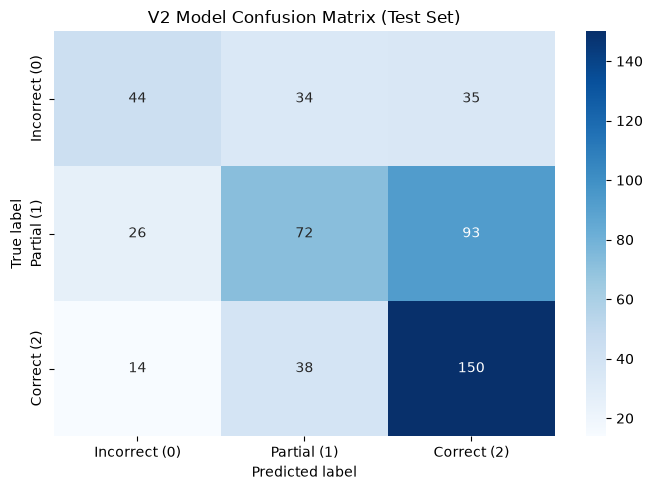

In [24]:
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Incorrect (0)", "Partial (1)", "Correct (2)"],
    yticklabels=["Incorrect (0)", "Partial (1)", "Correct (2)"],
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("V2 Model Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()


## Error Analysis

Identify incorrect predictions, calculate prediction confidence and error rate, and categorize the different types of classification errors. 

In [25]:
error_df = test_df.copy()
error_df["predicted_score"] = y_pred
error_df["confidence"] = y_proba.max(axis=1)

error_df["error_type"] = np.select(
    [
        (error_df["score"] == 0) & (error_df["predicted_score"] == 1),
        (error_df["score"] == 0) & (error_df["predicted_score"] == 2),
        (error_df["score"] == 1) & (error_df["predicted_score"] == 0),
        (error_df["score"] == 1) & (error_df["predicted_score"] == 2),
        (error_df["score"] == 2) & (error_df["predicted_score"] == 0),
        (error_df["score"] == 2) & (error_df["predicted_score"] == 1),
    ],
    [
        "Incorrect → Partial",
        "Incorrect → Correct",
        "Partial → Incorrect",
        "Partial → Correct",
        "Correct → Incorrect",
        "Correct → Partial",
    ],
    default="Correct prediction",
)

errors_only = error_df[error_df["score"] != error_df["predicted_score"]].copy()

print("Total test examples:", len(error_df))
print("Total errors:", len(errors_only))
print("Error rate:", round(len(errors_only) / len(error_df), 4))
errors_only["error_type"].value_counts()


Total test examples: 506
Total errors: 240
Error rate: 0.4743


error_type
Partial → Correct      93
Correct → Partial      38
Incorrect → Correct    35
Incorrect → Partial    34
Partial → Incorrect    26
Correct → Incorrect    14
Name: count, dtype: int64


## Partial → Correct Errors

Inspect cases where the true label is **Partially correct**, but the model predicts **Correct**. 

In [26]:
partial_to_correct = errors_only[
    (errors_only["score"] == 1) &
    (errors_only["predicted_score"] == 2)
].copy()

print("Partial → Correct cases:", len(partial_to_correct))

partial_to_correct[
    [
        "question",
        "student_answer",
        "reference_answer",
        "score",
        "predicted_score",
        "confidence",
    ]
].head(10)


Partial → Correct cases: 93


,question,student_answer,reference_answer,score,predicted_score,confidence
2,Q1. State TRUE or FALSE and justify. [6 marks]...,"True, spin until the spinlock is acquired, th...",FALSE\nIf the lock is available a spinlock doe...,1,2,0.719634
3,Q1. State TRUE or FALSE and justify. [6 marks]...,"True. Before the lock is acquired, we will do ...",FALSE\nIf the lock is available a spinlock doe...,1,2,0.592655
13,Q1. State TRUE or FALSE and justify. [6 marks]...,"False, the OS interacts with devices via CPU u...",FALSE\nThe ISA is an abstraction ins...,1,2,0.545410
16,What are the key assumptions of Muskingum floo...,Assumption of Muskingum flood routing method. ...,The Muskingum assumes singles stage. It has th...,1,2,0.529203
19,Q1. State TRUE or FALSE and justify. [6 marks]...,"FALSE, ISA is an abstraction provided by CPU r...",FALSE\nThe ISA is an abstraction ins...,1,2,0.568031
20,Q1. State TRUE or FALSE and justify. [6 marks]...,False. Instruction set is not an abstraction p...,FALSE\nThe ISA is an abstraction ins...,1,2,0.509274
24,Q1. State TRUE or FALSE and justify. [6 marks]...,True. spinlock involves polling value of a var...,FALSE\nIf the lock is available a spinlock doe...,1,2,0.621449
26,Q1. State TRUE or FALSE and justify. [6 marks]...,"True. Spinlock contains a while loop, which sp...",FALSE\nIf the lock is available a spinlock doe...,1,2,0.654552
28,Q1. State TRUE or FALSE and justify. [6 marks]...,"-> True\nIn spinlocks, a thread/threads tryin...",FALSE\nIf the lock is available a spinlock doe...,1,2,0.687177
33,Q1. State TRUE or FALSE and justify. [6 marks]...,True: Spinning happens until the status of th...,FALSE\nIf the lock is available a spinlock doe...,1,2,0.522755



## Error Summary

Summarize the different error types by their count and percentage of all errors. 

In [27]:
error_summary = (
    errors_only["error_type"]
    .value_counts()
    .rename_axis("Error Type")
    .reset_index(name="Count")
)

error_summary["Percentage"] = (
    error_summary["Count"] / len(errors_only) * 100
).round(2)

error_summary


,Error Type,Count,Percentage
0,Partial → Correct,93,38.75
1,Correct → Partial,38,15.83
2,Incorrect → Correct,35,14.58
3,Incorrect → Partial,34,14.17
4,Partial → Incorrect,26,10.83
5,Correct → Incorrect,14,5.83



## Incorrect → Correct Errors

Inspect cases where the true label is **Incorrect**, but the model predicts **Correct**. 

In [28]:
incorrect_to_correct = errors_only[(errors_only["score"] == 0) & (errors_only["predicted_score"] == 2)].copy()
print("Incorrect → Correct cases:", len(incorrect_to_correct))

incorrect_to_correct[["question", "student_answer", "reference_answer", "score", "predicted_score", "confidence"]].head(10)

Incorrect → Correct cases: 35


,question,student_answer,reference_answer,score,predicted_score,confidence
5,Q1. State TRUE or FALSE and justify. [6 marks]...,False. Abstractions are provided by the hardwa...,FALSE\nThe ISA is an abstraction ins...,0,2,0.576486
6,In what situation a canal fall is provided?,when there is a chance for water in the canal ...,When the natural slope of the region is more t...,0,2,0.461725
25,What is the role of edge direction in Harris C...,In Harris corner detection algorithms the vari...,The role of edge direction in Harris Corner de...,0,2,0.648959
27,Q1. State TRUE or FALSE and justify. [6 marks]...,False ISA is an abstraction provided by the CP...,FALSE\nThe ISA is an abstraction ins...,0,2,0.538333
44,What is the role of edge direction in Harris C...,"In Harris corner detector algorithm, edge dire...",The role of edge direction in Harris Corner de...,0,2,0.609459
74,Q1. State TRUE or FALSE and justify. [6 marks]...,Ans - True. ISA is not an abstraction provided...,FALSE\nThe ISA is an abstraction ins...,0,2,0.512486
77,A rating curve is only valid when?,The Rating curve will not be correct if its ex...,A rating curve is only valid when there is no ...,0,2,0.675947
93,Q1. State TRUE or FALSE and justify. [6 marks]...,"True, processes do not go to sleep + keep spin...",FALSE\nIf the lock is available a spinlock doe...,0,2,0.465149
98,What is the role of edge direction in Harris C...,The role of edge direction in Harris Corner de...,The role of edge direction in Harris Corner de...,0,2,0.640659
106,What is the role of edge direction in Harris C...,"In the Harris corner Detector Algorithm, there...",The role of edge direction in Harris Corner de...,0,2,0.722946



## Correct → Partial Errors

Inspect cases where the true label is **Correct**, but the model predicts **Partially correct**. 

In [29]:
correct_to_partial = errors_only[(errors_only["score"] == 2) & (errors_only["predicted_score"] == 1)].copy()
print("Correct → Partial cases:", len(correct_to_partial))

correct_to_partial[["question", "student_answer", "reference_answer", "score", "predicted_score", "confidence"]].head(10)

Correct → Partial cases: 38


,question,student_answer,reference_answer,score,predicted_score,confidence
8,List any two advantages of industry 4.0.,"Faster manufacturing, less wastage",1. Superior quality products can be manufactur...,2,1,0.465336
18,Q1. State TRUE or FALSE and justify. [6 marks]...,"False. If there is only one, power by both and...",FALSE\nIf the lock is available a spinlock doe...,2,1,0.419433
35,List any two advantages of industry 4.0.,"reduced manual labour, more accurate manufactu...",1. Superior quality products can be manufactur...,2,1,0.464389
76,Q1. State TRUE or FALSE and justify. [6 marks]...,False - knowing that you are user of the abstr...,FALSE\nThe ISA is an abstraction ins...,2,1,0.431663
88,During coagulation process alkalinity reduces ...,le chateliers principle so more hydrolysis inc...,"As coagulation is done,the OH- tend to form mo...",2,1,0.393886
89,List any two advantages of industry 4.0.,1) less manpower and higher efficiency due to ...,1. Superior quality products can be manufactur...,2,1,0.462920
97,What is vapor pressure deficit?,difference between saturate and actual vapor p...,the difference between the amount of moisture ...,2,1,0.377239
109,What are the factors that affect the evaporati...,"surface area of body, depth of body, vapour pr...","Wind Speed, Temperature of water and air, vapo...",2,1,0.442080
117,Q1. State TRUE or FALSE and justify. [6 marks]...,True It spins for infinite time (to get lock)...,FALSE\nIf the lock is available a spinlock doe...,2,1,0.432417
127,Q1. State TRUE or FALSE and justify. [6 marks]...,"False, it is an abstraction as OS just interac...",FALSE\nThe ISA is an abstraction ins...,2,1,0.454564



## Prediction Confidence

Compare the model's confidence for correct and incorrect predictions using summary statistics. 

In [30]:
error_df["correct_prediction"] = (error_df["score"] == error_df["predicted_score"])
confidence_summary = (error_df.groupby("correct_prediction")["confidence"].agg(["count", "mean", "median", "min", "max"]).round(4))

confidence_summary

,count,mean,median,min,max
correct_prediction,,,,,
False,240,0.5177,0.4983,0.3448,0.8840
True,266,0.5854,0.5669,0.3728,0.9228



## Confidence Comparison

Compare the average prediction confidence between correct and incorrect predictions.

In [31]:
print(f"Average confidence for correct predictions: {error_df.loc[error_df['correct_prediction'], 'confidence'].mean():.4f}")
print(f"Average confidence for incorrect predictions: {error_df.loc[~error_df['correct_prediction'], 'confidence'].mean():.4f}")

Average confidence for correct predictions: 0.5854
Average confidence for incorrect predictions: 0.5177


## Robustness and Failure Patterns

The error analysis shows that the model does not make all types of mistakes equally often. The largest error category is partial answers being classified as fully correct. This suggests that semantic similarity can sometimes cause an answer to be considered sufficiently similar to the reference even when some important information is missing.

Other errors occur when incorrect answers are classified as correct or partially correct. This can happen when an incorrect answer contains words or concepts that are semantically similar to the reference answer.

The confidence analysis also shows that incorrect predictions generally have lower confidence than correct predictions. However, the overlap between the confidence values indicates that confidence alone cannot reliably identify every incorrect prediction.

These observations are important for robustness because they show that the model can be affected by incomplete answers, semantically similar but incorrect answers, and differences in how students express the same concept.


## Representative Failure Cases

The following examples are selected from the test set to illustrate common failure patterns. They are representative examples rather than an exhaustive list of all model errors.


In [32]:
selected_cases = [
    {
        "topic": "Spinlock",
        "score": 1,
        "predicted_score": 2,
        "keywords": "spinlock",
    },
    {
        "topic": "ISA",
        "score": 0,
        "predicted_score": 2,
        "keywords": r"\bISA\b|instruction set architecture",
    },
    {
        "topic": "Canal fall situation",
        "score": 0,
        "predicted_score": 2,
        "keywords": "canal fall",
    },
    {
        "topic": "Harris corner detection",
        "score": 0,
        "predicted_score": 2,
        "keywords": "Harris corner",
    },
    {
        "topic": "Industry 4.0 advantages",
        "score": 2,
        "predicted_score": 1,
        "keywords": "Industry 4.0",
    },

    {
        "topic": "Rating curve validity",
        "score": 0,
        "predicted_score": 2,
        "keywords": "rating curve",
    },
    {
        "topic": "Coagulation and alkalinity",
        "score": 2,
        "predicted_score": 1,
        "keywords": "coagulation",
    },
    {
        "topic": "Vapour pressure deficit",
        "score": 2,
        "predicted_score": 1,
        "keywords": r"vapor pressure deficit|vapour pressure deficit",
    },
    {
        "topic": "Evaporation factors",
        "score": 2,
        "predicted_score": 1,
        "keywords": "factors that affect the evaporation",
    },
    {
        "topic": "Muskingum flood routing",
        "score": 1,
        "predicted_score": 2,
        "keywords": "Muskingum",
    },
]

failure_cases_list = []

for case in selected_cases:
    topic = case["topic"]

    # Find errors with the required true and predicted scores
    candidates = error_df[
        (error_df["score"] == case["score"]) &
        (error_df["predicted_score"] == case["predicted_score"])
    ].copy()

    # Match the topic against the question text
    candidates = candidates[
        candidates["question"].str.contains(
            case["keywords"],
            case=False,
            na=False,
            regex=True)]

    if candidates.empty:
        print(f"No matching failure found for: {topic}")
        continue

    # Select the highest-confidence genuine error
    chosen = candidates.sort_values(
        "confidence", ascending=False
    ).head(1).copy()

    chosen["topic"] = topic
    failure_cases_list.append(chosen)

# Combine the selected cases
if failure_cases_list:
    failure_cases = pd.concat(
        failure_cases_list,
        ignore_index=True,
    )

    display(failure_cases[
            ["topic", "question", "student_answer", "reference_answer", "score", "predicted_score", "confidence"]])

    print("Number of selected cases:", len(failure_cases))
    print("Number of unique topics:", failure_cases["topic"].nunique())

    # Check whether all 10 topics were found
    found_topics = set(failure_cases["topic"])
    missing_topics = [
        case["topic"]
        for case in selected_cases
        if case["topic"] not in found_topics
    ]

    if missing_topics:
        print("Topics without matching errors:", missing_topics)
    else:
        print("Success: all 10 topics have representative errors.")

else:
    print("No matching failure cases were found.")

,topic,question,student_answer,reference_answer,score,predicted_score,confidence
0,Spinlock,Q1. State TRUE or FALSE and justify. [6 marks]...,"True, A spinlock is called spinlock because we...",FALSE\nIf the lock is available a spinlock doe...,1,2,0.725385
1,ISA,Q1. State TRUE or FALSE and justify. [6 marks]...,False. Abstractions are provided by the hardwa...,FALSE\nThe ISA is an abstraction ins...,0,2,0.576486
2,Canal fall situation,In what situation a canal fall is provided?,when there is a chance for water in the canal ...,When the natural slope of the region is more t...,0,2,0.461725
3,Harris corner detection,What is the role of edge direction in Harris C...,"In the Harris corner Detector Algorithm, there...",The role of edge direction in Harris Corner de...,0,2,0.722946
4,Industry 4.0 advantages,List any two advantages of industry 4.0.,"Faster manufacturing, less wastage",1. Superior quality products can be manufactur...,2,1,0.465336
5,Rating curve validity,A rating curve is only valid when?,The Rating curve will not be correct if its ex...,A rating curve is only valid when there is no ...,0,2,0.675947
6,Coagulation and alkalinity,During coagulation process alkalinity reduces ...,le chateliers principle so more hydrolysis inc...,"As coagulation is done,the OH- tend to form mo...",2,1,0.393886
7,Vapour pressure deficit,What is vapor pressure deficit?,difference between saturate and actual vapor p...,the difference between the amount of moisture ...,2,1,0.377239
8,Evaporation factors,What are the factors that affect the evaporati...,"surface area of body, depth of body, temperatu...","Wind Speed, Temperature of water and air, vapo...",2,1,0.446079
9,Muskingum flood routing,What are the key assumptions of Muskingum floo...,Assumption of Muskingum flood routing method. ...,The Muskingum assumes singles stage. It has th...,1,2,0.529203


Number of selected cases: 10
Number of unique topics: 10
Success: all 10 topics have representative errors.


Case 1 - Partial Answer Predicted as Correct (Spinlock)

The student answer was labelled partially correct, but the model predicted it as correct. The answer discusses spinning until a spinlock is acquired, which is relevant to the reference answer, but the model may have treated this similarity as sufficient for a correct prediction.

Error type: Partial → Correct
True score: 1
Predicted score: 2

Case 2 - Incorrect Answer Predicted as Correct (ISA)

The student's answer about Instruction Set Architecture (ISA) was labelled incorrect but predicted as correct. The answer contains terminology related to hardware abstractions, which may have contributed to the model's prediction.

Error type: Incorrect → Correct
True score: 0
Predicted score: 2

Case 3 - Incorrect Answer Predicted as Correct (Canal Fall Situation)

The student's answer about when a canal fall is provided was labelled incorrect, but the model predicted it as correct. Although the answer refers to water in a canal, it may not adequately explain the specific conditions required by the reference answer.

Error type: Incorrect → Correct
True score: 0
Predicted score: 2

Case 4 - Incorrect Answer Predicted as Correct (Harris Corner Detection)

The answer concerning the role of edge direction in Harris corner detection was labelled incorrect but predicted as correct. The model may have recognised relevant computer vision terminology without correctly evaluating the explanation.

Error type: Incorrect → Correct
True score: 0
Predicted score: 2

Case 5 - Correct Answer Predicted as Partially Correct (Industry 4.0 Advantages)

The student's answer mentioned advantages of Industry 4.0, including faster manufacturing and reduced wastage. Although the answer was labelled correct, the model predicted it as partially correct, possibly because the response differed from the reference answer's wording.

Error type: Correct → Partial
True score: 2
Predicted score: 1

Case 6 - Incorrect Answer Predicted as Correct (Rating Curve Validity)

The student's answer about rating curve validity was labelled incorrect but predicted as correct. The response discusses circumstances in which a rating curve may be unreliable, but the model may not have adequately evaluated whether it correctly addressed the question.

Error type: Incorrect → Correct
True score: 0
Predicted score: 2

Case 7 - Correct Answer Predicted as Partially Correct (Coagulation and Alkalinity)

The student's answer concerning the reduction of alkalinity during coagulation was labelled correct but predicted as partially correct. The response refers to the relevant chemical process, suggesting that the model may have underestimated the correctness of the explanation.

Error type: Correct → Partial
True score: 2
Predicted score: 1

Case 8 — Correct Answer Predicted as Partially Correct (Vapour Pressure Deficit)

The student's answer defined vapour pressure deficit in terms of the difference between saturated and actual vapour pressure. Although labelled correct, it was predicted as partially correct, indicating a possible difficulty in recognising a valid scientific definition.

Error type: Correct → Partial
True score: 2
Predicted score: 1

Case 9 — Correct Answer Predicted as Partially Correct (Factors Affecting Evaporation)

The student identified factors affecting evaporation, including surface area, water depth and vapour pressure. The answer was labelled correct, but the model predicted it as partially correct, potentially because the listed factors differed from those in the reference answer.

Error type: Correct → Partial
True score: 2
Predicted score: 1

Case 10 — Partial Answer Predicted as Correct (Muskingum Flood Routing)

The student's answer about the assumptions of the Muskingum flood routing method was labelled partially correct but predicted as correct. The model may have recognised the relevant method without adequately evaluating whether the answer included all the required assumptions.

Error type: Partial → Correct
True score: 1
Predicted score: 2

#  Conclusion

The Week 4 hybrid NLP model was evaluated on the held-out EngSAF test set containing 506 student answers.

The model achieved an accuracy of 52.57%, a Macro-F1 score of 0.5005, a quadratic weighted kappa (QWK) of 0.3643, and a mean absolute error (MAE) of 0.5711. The recall for the partially correct class was 37.70%.

The confusion matrix shows that the model made 240 incorrect predictions out of 506 test examples. The most frequent error was predicting a partially correct answer as correct, with 93 cases. There were also 35 cases where an incorrect answer was predicted as correct, representing a serious two-level grading error. Conversely, 38 correct answers were predicted as partially correct.

The error analysis examined 10 distinct topics across different subject areas, including spinlocks, Instruction Set Architecture (ISA), canal falls, Harris corner detection, Industry 4.0, rating curve validity, coagulation and alkalinity, vapour pressure deficit, evaporation, and Muskingum flood routing. These examples illustrate different ways in which the model can misclassify student answers.

The selected cases highlight two major limitations: over-grading and under-grading. Over-grading occurs when the model assigns a higher score than the answer deserves, such as predicting an incorrect answer as correct or a partially correct answer as correct. Under-grading occurs when a correct answer is classified as partially correct. These errors may arise when the model recognises relevant terminology or semantic similarity without fully evaluating the correctness and completeness of the response.

The confidence analysis provides additional evidence of uncertainty. Correct predictions had an average confidence of 0.5854, compared with 0.5177 for incorrect predictions. Although confidence was higher on average for correct predictions, the overlap between the two groups indicates that confidence alone is insufficient to reliably identify incorrect predictions.

Overall, the evaluation demonstrates that the hybrid feature approach can identify meaningful semantic relationships between student and reference answers, but it still struggles to distinguish between partially correct and fully correct responses. Future improvements could focus on better key-point coverage, handling negation and contradictions, question-specific evaluation, and more effective assessment of incomplete or semantically similar incorrect answers.